# Stellar Kinematics in M4
#### A Gaia DR2 Investigation of Proper-Motion Dispersion

**Danessa Ruff**  
Michigan State University | Astrophysics  
*Independent extension of AST 208 coursework*

---

## Overview

In AST 208, I worked with Gaia data to identify possible members of the globular cluster M4 using proper motions and parallaxes.

I wanted to take that analysis further and see whether stars closer to the center of M4 have a different spread in their motions than stars farther away.

I used the same dataset to compare proper-motion dispersion at different distances from the cluster center. I also checked how the results changed when I adjusted the membership selection and limited the sample to stars with smaller measurement uncertainties.

## Research Question

How does stellar proper-motion dispersion vary with projected distance from the center of M4?

## Data

I used Gaia Data Release 2 (DR2) data from Gaia Collaboration (2018). The dataset, `m4.dat`, was provided by Dr. Joey Rodriguez for AST 208 at Michigan State University.

The file contains 104,734 stars in the region around M4. For this project, I used their positions, parallaxes, proper motions, and measurement uncertainties.

Positions are given in degrees, parallaxes in milliarcseconds (mas), and proper motions in milliarcseconds per year (mas/yr).

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [17]:
data = np.genfromtxt("m4.dat", skip_header=67, delimiter=";")

ra = data[:, 0]
dec = data[:, 1]
parallax = data[:, 2]
parallax_err = data[:, 3]

pmra = data[:, 4]
pmra_err = data[:, 5]
pmdec = data[:, 6]
pmdec_err = data[:, 7]

print("Total stars:", len(ra))
print("Data shape:", data.shape)

Total stars: 104734
Data shape: (104734, 14)


## Selecting M4 Candidates

I started by plotting the proper motions of stars in the M4 field. The cluster appears as a concentration near −13 mas/yr in RA and −19 mas/yr in Dec, separate from much of the surrounding field population.

I used a circular cutoff of 3 mas/yr around this concentration to select possible cluster members. This gives me an initial sample, although some field stars may still be included.

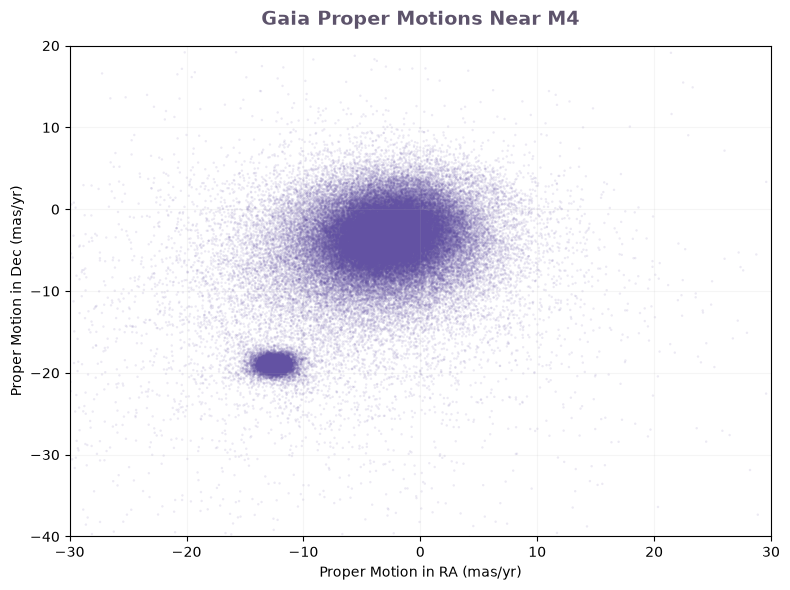

In [18]:
#plots proper motions of stars
valid = np.isfinite(pmra) & np.isfinite(pmdec)

plt.figure(figsize=(8, 6))
plt.scatter(pmra[valid], pmdec[valid], s=3, color="#6352A3", alpha=0.12, edgecolors="none", rasterized=True)
plt.xlabel("Proper Motion in RA (mas/yr)")
plt.ylabel("Proper Motion in Dec (mas/yr)")
plt.title("Gaia Proper Motions Near M4", color="#5D536B", fontsize=14, fontweight="bold", pad=15)
plt.xlim(-30, 30)
plt.ylim(-40, 20)
plt.grid(alpha=0.12)
plt.tight_layout()
plt.show()

In [19]:
#selects stars near M4 proper-motion concentration
pm_distance = np.sqrt((pmra + 13)**2 + (pmdec + 19)**2)
members = valid & (pm_distance < 3)
print("Initial M4 candidates:", np.sum(members))

Initial M4 candidates: 18280


## Checking the Candidate Sample

The proper-motion selection identified 18,280 possible M4 members. Since similar proper motions alone don't guarantee cluster membership, I'll examine their parallaxes to see whether the selected stars form a consistent population.

In [20]:
#checks parallax distribution
good_parallax = np.isfinite(parallax)
median_parallax = np.median(parallax[members & good_parallax])
print("Median candidate parallax:", round(median_parallax, 3), "mas")

Median candidate parallax: 0.508 mas


Original candidates: 18280
After parallax selection: 13704


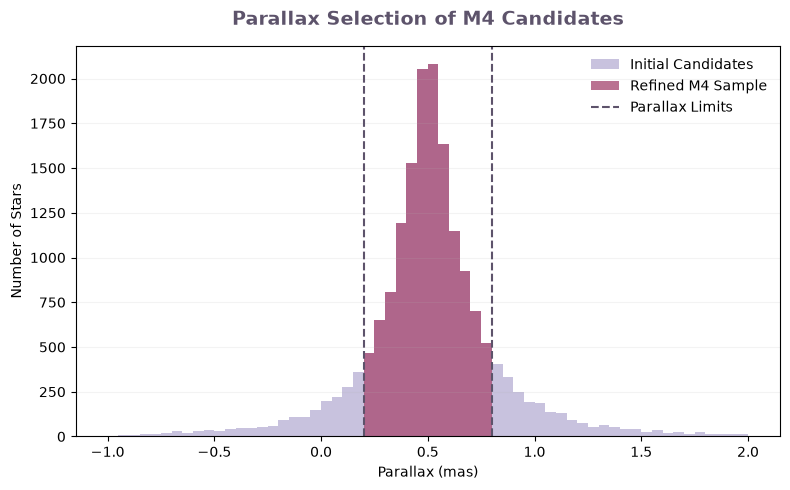

In [21]:
#refines sample using parallax
m4 = members & (parallax > 0.2) & (parallax < 0.8)

print("Original candidates:", np.sum(members))
print("After parallax selection:", np.sum(m4))

plt.figure(figsize=(8, 5))
plt.hist(parallax[members & good_parallax], bins=60, range=(-1, 2), color="#6352A3", alpha=0.35, label="Initial Candidates")
plt.hist(parallax[m4 & good_parallax], bins=60, range=(-1, 2), color="#A94F76", alpha=0.8, label="Refined M4 Sample")

plt.axvline(0.2, color="#5D536B", linestyle="--", linewidth=1.5)
plt.axvline(0.8, color="#5D536B", linestyle="--", linewidth=1.5, label="Parallax Limits")

plt.xlabel("Parallax (mas)")
plt.ylabel("Number of Stars")
plt.title("Parallax Selection of M4 Candidates", color="#5D536B", fontsize=14, fontweight="bold", pad=15)
plt.grid(axis="y", alpha=0.15)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

## Spatial Distribution of M4 Candidates

Next, I plotted the positions of the selected stars to see whether they were grouped around M4.

The stars were concentrated in one area, which supported my initial selection. I used the median RA and Dec of these stars to estimate the cluster's center.

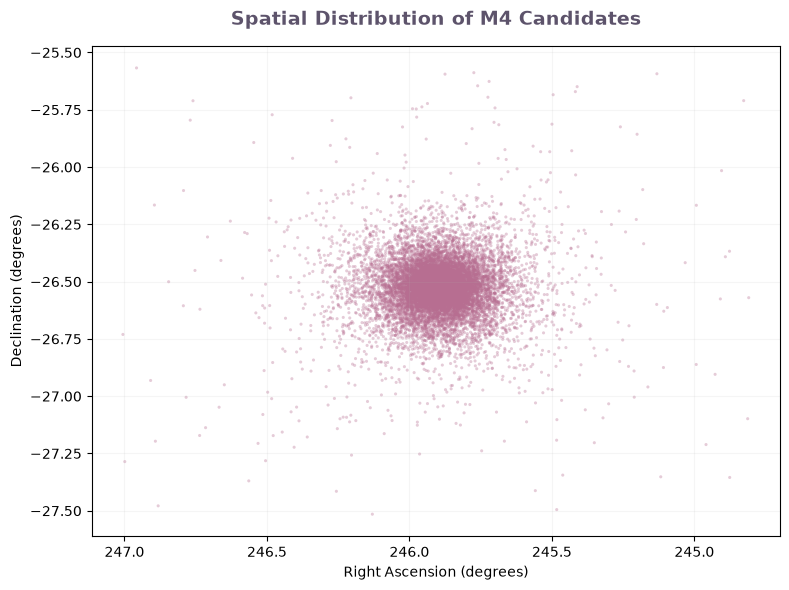

Stars with valid positions: 13704
Median RA: 245.8951
Median Dec: -26.5252


In [22]:
#examines positions of selected stars
good_position = m4 & np.isfinite(ra) & np.isfinite(dec)

plt.figure(figsize=(8, 6))
plt.scatter(ra[good_position], dec[good_position], s=5, color="#B76E91", alpha=0.35, edgecolors="none")

plt.xlabel("Right Ascension (degrees)")
plt.ylabel("Declination (degrees)")
plt.title("Spatial Distribution of M4 Candidates", color="#5D536B", fontsize=14, fontweight="bold", pad=15)

plt.grid(alpha=0.12)
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

print("Stars with valid positions:", np.sum(good_position))
print("Median RA:", round(np.median(ra[good_position]), 4))
print("Median Dec:", round(np.median(dec[good_position]), 4))

## Distance from the Cluster Center

To examine how proper-motion dispersion varies across M4, I calculated the projected angular distance of each candidate star from the cluster center.

I estimated the center using the median right ascension and declination of the selected sample. I then calculated the angular separation in arcminutes, accounting for the effect of declination on right ascension.

These distances allowed me to divide the sample into radial regions and compare the proper-motion dispersion at different distances from the center.

Median radius: 5.98 arcmin
Maximum radius: 80.97 arcmin


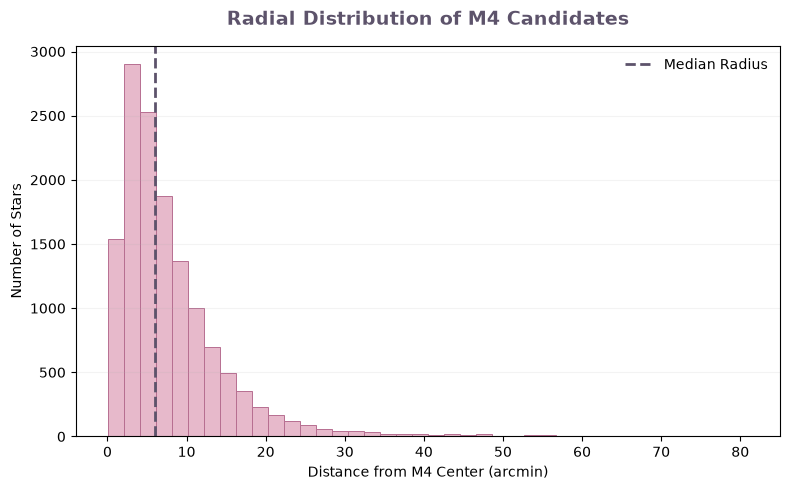

In [23]:
#estimates center of M4
ra_center = np.median(ra[good_position])
dec_center = np.median(dec[good_position])

#calculates angular distance from center
dx = (ra[good_position] - ra_center) * np.cos(np.radians(dec_center))
dy = dec[good_position] - dec_center

radius_arcmin = np.sqrt(dx**2 + dy**2) * 60

print("Median radius:", round(np.median(radius_arcmin), 2), "arcmin")
print("Maximum radius:", round(np.max(radius_arcmin), 2), "arcmin")

plt.figure(figsize=(8, 5))
plt.hist(radius_arcmin, bins=40, color="#E7B9CB", edgecolor="#B76E91", linewidth=0.7)
plt.axvline(np.median(radius_arcmin), color="#5D536B", linestyle="--", linewidth=2, label="Median Radius")

plt.xlabel("Distance from M4 Center (arcmin)")
plt.ylabel("Number of Stars")
plt.title("Radial Distribution of M4 Candidates", color="#5D536B", fontsize=14, fontweight="bold", pad=15)
plt.grid(axis="y", alpha=0.15)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

## Comparing Stellar Motions at Different Radii

I divided the M4 candidates into two radial regions: an inner sample within 5 arcminutes of the estimated cluster center and an outer sample between 5 and 20 arcminutes.

I compared their proper-motion distributions in RA and Dec to see whether the spread in stellar motions differed between the two regions. This gives an initial comparison before calculating the dispersion values.

Inner stars: 5668
Outer stars: 7284


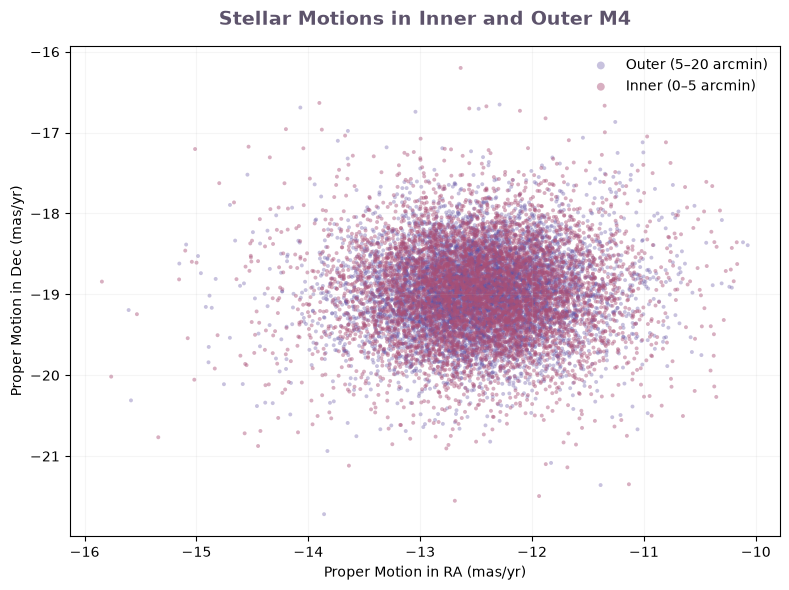

In [24]:
# Compare proper motions near and farther from the center
inner = good_position.copy()
outer = good_position.copy()

inner[good_position] = radius_arcmin < 5
outer[good_position] = (radius_arcmin >= 5) & (radius_arcmin < 20)

print("Inner stars:", np.sum(inner))
print("Outer stars:", np.sum(outer))

plt.figure(figsize=(8, 6))
plt.scatter(pmra[outer], pmdec[outer], s=8, color="#6352A3", alpha=0.35, edgecolors="none", label="Outer (5–20 arcmin)")
plt.scatter(pmra[inner], pmdec[inner], s=8, color="#A94F76", alpha=0.45, edgecolors="none", label="Inner (0–5 arcmin)")

plt.xlabel("Proper Motion in RA (mas/yr)")
plt.ylabel("Proper Motion in Dec (mas/yr)")
plt.title("Stellar Motions in Inner and Outer M4", color="#5D536B", fontsize=14, fontweight="bold", pad=15)
plt.grid(alpha=0.12)
plt.legend(frameon=False, markerscale=2)
plt.tight_layout()
plt.show()

## Measuring Proper-Motion Dispersion

To quantify the differences between the inner and outer regions, I calculated the standard deviation of stellar proper motions in right ascension (RA) and declination (Dec).

A larger standard deviation indicates a greater spread in measured stellar motions.

Comparing these values allows me to test whether the central region of M4 has a larger proper-motion dispersion than the surrounding stars.

In [25]:
#measures proper-motion dispersion in each region
for name, stars in [("Inner", inner), ("Outer", outer)]:
    sigma_ra = np.std(pmra[stars])
    sigma_dec = np.std(pmdec[stars])
    print(name, "region:")
    print("RA dispersion:", round(sigma_ra, 3), "mas/yr")
    print("Dec dispersion:", round(sigma_dec, 3), "mas/yr")
    print()

Inner region:
RA dispersion: 0.692 mas/yr
Dec dispersion: 0.607 mas/yr

Outer region:
RA dispersion: 0.587 mas/yr
Dec dispersion: 0.501 mas/yr



## Accounting for Measurement Uncertainties

The observed proper-motion dispersion includes both differences in stellar motions and uncertainty in Gaia's measurements.

To investigate how much measurement uncertainty might affect my results, I compared the reported proper-motion errors in the inner and outer regions.

I calculated the median and root-mean-square (RMS) uncertainties for both proper-motion components. The RMS values will also be useful when estimating the dispersion after accounting for measurement errors.

In [26]:
#compares proper-motion uncertainties in each region
for name, stars in [("Inner", inner), ("Outer", outer)]:
    ra_errors = pmra_err[stars]
    dec_errors = pmdec_err[stars]

    ra_errors = ra_errors[np.isfinite(ra_errors) & (ra_errors > 0)]
    dec_errors = dec_errors[np.isfinite(dec_errors) & (dec_errors > 0)]

    print(name, "region:")
    print("Median RA error:", round(np.median(ra_errors), 3), "mas/yr")
    print("Median Dec error:", round(np.median(dec_errors), 3), "mas/yr")
    print("RMS RA error:", round(np.sqrt(np.mean(ra_errors**2)), 3), "mas/yr")
    print("RMS Dec error:", round(np.sqrt(np.mean(dec_errors**2)), 3), "mas/yr")
    print()

Inner region:
Median RA error: 0.258 mas/yr
Median Dec error: 0.18 mas/yr
RMS RA error: 0.395 mas/yr
RMS Dec error: 0.277 mas/yr

Outer region:
Median RA error: 0.302 mas/yr
Median Dec error: 0.205 mas/yr
RMS RA error: 0.412 mas/yr
RMS Dec error: 0.28 mas/yr



## Estimating Measurement-Error-Corrected Dispersion

The observed proper-motion dispersion includes contributions from Gaia's measurement uncertainties.

To estimate the dispersion after accounting for these uncertainties, I subtracted the mean squared measurement error from the observed variance and took the square root.

This is an approximate correction. It does not fully account for possible field-star contamination, membership-selection effects, or differences in measurement quality between individual stars.

I used these corrected estimates to compare stellar motions in the inner and outer regions of M4.

In [27]:
#estimates dispersion after accounting for measurement errors
for name, stars in [("Inner", inner), ("Outer", outer)]:
    valid_errors = (np.isfinite(pmra_err) & np.isfinite(pmdec_err) & (pmra_err > 0) & (pmdec_err > 0))
    sample = stars & valid_errors

    sigma_ra = np.std(pmra[sample])
    sigma_dec = np.std(pmdec[sample])

    error_ra = np.mean(pmra_err[sample]**2)
    error_dec = np.mean(pmdec_err[sample]**2)

    corrected_ra = np.sqrt(max(0, sigma_ra**2 - error_ra))
    corrected_dec = np.sqrt(max(0, sigma_dec**2 - error_dec))

    print(name, "region:")
    print("Corrected RA dispersion:", round(corrected_ra, 3), "mas/yr")
    print("Corrected Dec dispersion:", round(corrected_dec, 3), "mas/yr")
    print()

Inner region:
Corrected RA dispersion: 0.568 mas/yr
Corrected Dec dispersion: 0.54 mas/yr

Outer region:
Corrected RA dispersion: 0.417 mas/yr
Corrected Dec dispersion: 0.415 mas/yr



## Radial Proper-Motion Dispersion Profile

To investigate how stellar motions change across M4, I divided the selected stars into radial bins of 4 arcminutes, extending from the center to 20 arcminutes.

For each bin, I calculated the proper-motion dispersion in RA and Dec and applied the approximate correction for Gaia measurement uncertainties.

I then plotted the corrected dispersion against projected distance from the cluster center to examine whether the spread in stellar motions changes with radius.

0-4 arcmin: 4341 stars
4-8 arcmin: 4406 stars
8-12 arcmin: 2392 stars
12-16 arcmin: 1224 stars
16-20 arcmin: 589 stars


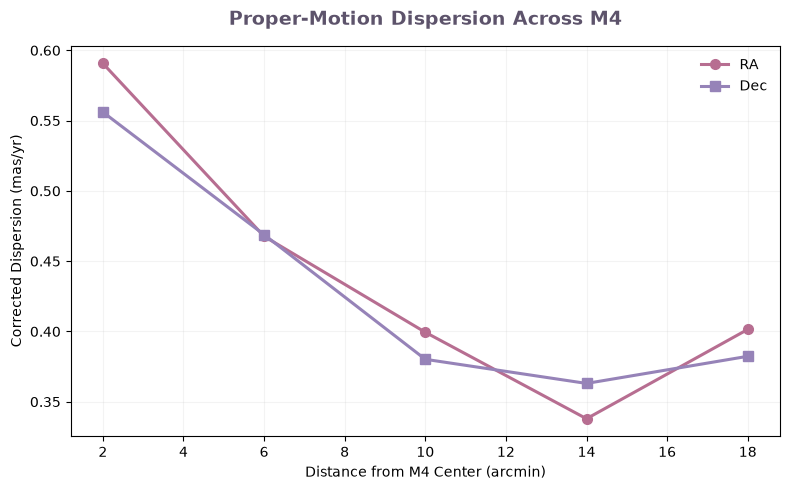

In [31]:
#calculates dispersion in 4-arcminute intervals
radii = []
sigma_ra_values = []
sigma_dec_values = []

for r in range(0, 20, 4):
    stars = good_position.copy()
    stars[good_position] = (radius_arcmin >= r) & (radius_arcmin < r + 4)
    stars = stars & np.isfinite(pmra_err) & np.isfinite(pmdec_err)
    stars = stars & (pmra_err > 0) & (pmdec_err > 0)

    if np.sum(stars) < 30:
        continue

    ra_var = np.var(pmra[stars]) - np.mean(pmra_err[stars]**2)
    dec_var = np.var(pmdec[stars]) - np.mean(pmdec_err[stars]**2)

    radii.append(r + 2)
    sigma_ra_values.append(np.sqrt(max(0, ra_var)))
    sigma_dec_values.append(np.sqrt(max(0, dec_var)))
    print(f"{r}-{r+4} arcmin: {np.sum(stars)} stars")

plt.figure(figsize=(8, 5))
plt.plot(radii, sigma_ra_values, "o-", color="#B76E91", linewidth=2.2, markersize=7, label="RA")
plt.plot(radii, sigma_dec_values, "s-", color="#9683B8", linewidth=2.2, markersize=7, label="Dec")

plt.xlabel("Distance from M4 Center (arcmin)")
plt.ylabel("Corrected Dispersion (mas/yr)")
plt.title("Proper-Motion Dispersion Across M4", color="#5D536B", fontsize=14, fontweight="bold", pad=15)

plt.grid(alpha=0.15)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

## Testing the Membership Selection

My initial sample includes stars within 3 mas/yr of M4's proper-motion concentration. Since this selection could influence the measured dispersion, I repeated the analysis using a narrower cutoff of 2 mas/yr.

I calculated the corrected proper-motion dispersion in the same radial bins and compared the results with the original sample.

This test helps determine whether the overall radial trend remains when the membership criteria change.

0 - 4 arcmin: 4182 stars
4 - 8 arcmin: 4313 stars
8 - 12 arcmin: 2353 stars
12 - 16 arcmin: 1207 stars
16 - 20 arcmin: 573 stars


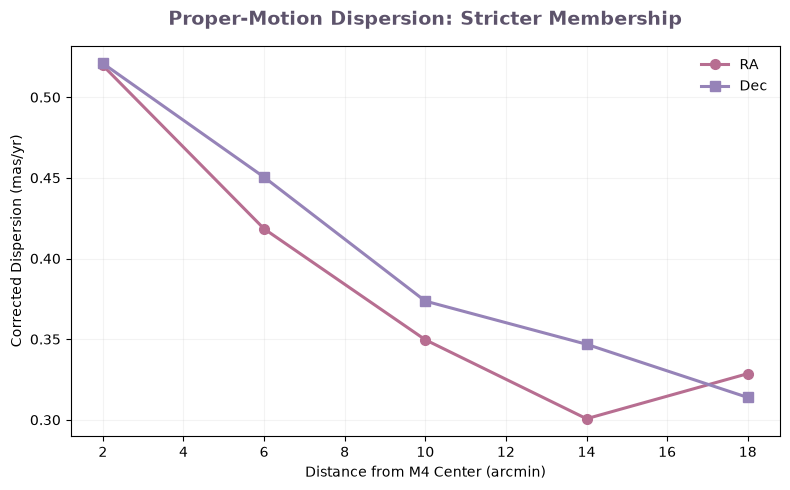

In [29]:
#repeats analysis with a stricter proper-motion selection
strict = good_position & (pm_distance < 2)

strict_ra = []
strict_dec = []

for r in range(0, 20, 4):
    stars = strict.copy()
    stars[good_position] = strict[good_position] & (radius_arcmin >= r) & (radius_arcmin < r + 4)
    stars = stars & np.isfinite(pmra_err) & np.isfinite(pmdec_err)
    stars = stars & (pmra_err > 0) & (pmdec_err > 0)

    ra_var = np.var(pmra[stars]) - np.mean(pmra_err[stars]**2)
    dec_var = np.var(pmdec[stars]) - np.mean(pmdec_err[stars]**2)

    strict_ra.append(np.sqrt(max(0, ra_var)))
    strict_dec.append(np.sqrt(max(0, dec_var)))
    print(r, "-", r+4, "arcmin:", np.sum(stars), "stars")
    
plt.figure(figsize=(8, 5))
plt.plot(radii, strict_ra, "o-", color="#B76E91", linewidth=2.2, markersize=7, label="RA")
plt.plot(radii, strict_dec, "s-", color="#9683B8", linewidth=2.2, markersize=7, label="Dec")
plt.xlabel("Distance from M4 Center (arcmin)")
plt.ylabel("Corrected Dispersion (mas/yr)")
plt.title("Proper-Motion Dispersion: Stricter Membership", color="#5D536B", fontsize=14, fontweight="bold", pad=15)
plt.grid(alpha=0.15)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

## Testing the Effect of Measurement Quality

To check whether stars with larger Gaia uncertainties were affecting the results, I repeated the radial-dispersion analysis using only stars with proper-motion errors below 0.3 mas/yr in both RA and Dec.

I kept the same radial bins and approximate measurement-error correction so the results could be compared with the original sample.

This provides an additional test of whether the observed radial trend depends on measurement quality.

0-4 arcmin: 2643 stars
4-8 arcmin: 2275 stars
8-12 arcmin: 1212 stars
12-16 arcmin: 577 stars
16-20 arcmin: 243 stars


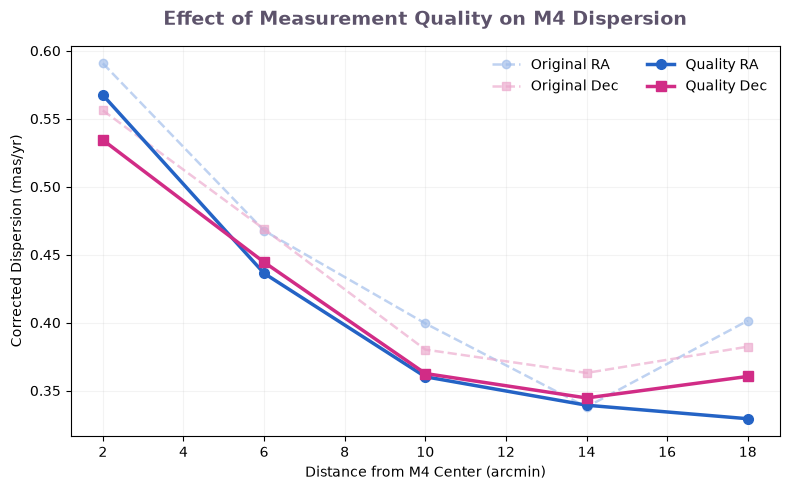

In [42]:
#keeps stars with smaller proper-motion uncertainties
quality = good_position & (pmra_err < 0.3) & (pmdec_err < 0.3)
quality = quality & (pmra_err > 0) & (pmdec_err > 0)

quality_radii = []
quality_ra = []
quality_dec = []

for r in range(0, 20, 4):
    stars = quality.copy()
    stars[good_position] = quality[good_position] & (radius_arcmin >= r) & (radius_arcmin < r + 4)
    if np.sum(stars) < 30:
        continue
    quality_radii.append(r + 2)
    
    ra_var = np.var(pmra[stars]) - np.mean(pmra_err[stars]**2)
    dec_var = np.var(pmdec[stars]) - np.mean(pmdec_err[stars]**2)

    quality_ra.append(np.sqrt(max(0, ra_var)))
    quality_dec.append(np.sqrt(max(0, dec_var)))
    print(f"{r}-{r+4} arcmin: {np.sum(stars)} stars")

plt.figure(figsize=(8, 5))

#original sample: dashed lines, pale colors
plt.plot(radii, sigma_ra_values, "o--", color="#9DBBEA", linewidth=1.8, markersize=6, alpha=0.65, label="Original RA")
plt.plot(radii, sigma_dec_values, "s--", color="#EBA6CB", linewidth=1.8, markersize=6, alpha=0.65, label="Original Dec")

#quality-filtered sample: solid lines, vibrant colors
plt.plot(radii, quality_ra, "o-", color="#2463C5", linewidth=2.5, markersize=7, label="Quality RA")
plt.plot(radii, quality_dec, "s-", color="#D12C86", linewidth=2.5, markersize=7, label="Quality Dec")

plt.xlabel("Distance from M4 Center (arcmin)")
plt.ylabel("Corrected Dispersion (mas/yr)")
plt.title("Effect of Measurement Quality on M4 Dispersion", color="#5D536B", fontsize=14, fontweight="bold", pad=15)
plt.grid(alpha=0.15)
plt.legend(frameon=False, ncol=2)
plt.tight_layout()
plt.show()

## Results and Discussion

The estimated proper-motion dispersion in M4 generally decreases with projected distance from the cluster center.

In the original sample, the innermost region (0–4 arcmin) had corrected dispersions of approximately 0.59 mas/yr in RA and 0.56 mas/yr in Dec. At 12–16 arcmin, these decreased to approximately 0.34 and 0.36 mas/yr.

The outermost region (16–20 arcmin) showed a slight increase in both components, so the trend was not strictly decreasing.

I repeated the analysis using a stricter proper-motion membership selection and a separate sample with smaller Gaia measurement uncertainties. Both tests preserved the overall decreasing trend, although the exact dispersion values changed.

The results show a higher estimated proper-motion dispersion near the center of M4, with a general decrease toward larger radii. However, the membership cuts and measurement uncertainties may affect the size of this difference, so I cannot conclude that the corrected values represent the cluster's intrinsic dispersion.


## Limitations and Future Work

The corrected dispersions are only approximate estimates. The membership cuts restrict the proper-motion distribution being measured, and possible field-star contamination, measurement uncertainties, and crowding could influence the results.

A more detailed analysis using probabilistic membership selection and improved statistical modeling could help distinguish M4's intrinsic stellar motions from measurement uncertainties.

## Conclusion

In this project, I expanded on my AST 208 work with Gaia data by investigating how stellar motions vary across the globular cluster M4.

I found that the estimated proper-motion dispersion is generally higher near the cluster center and decreases toward larger projected distances. This pattern remained when I used a stricter membership selection and restricted the analysis to stars with smaller measurement uncertainties.

This investigation demonstrates how Gaia data can be used to explore the internal kinematics of a globular cluster, beyond simply identifying its members.

---

## Credits & Acknowledgments

**Data Source:** Gaia Data Release 2 (DR2), Gaia Collaboration (2018).

**Data Provided By:** Dr. Joey Rodriguez, Michigan State University. The `m4.dat` dataset was provided as part of AST 208 coursework.

**Academic Background:** This project builds on concepts introduced in AST 208 at Michigan State University, including Gaia astrometry and globular cluster membership selection.

**Independent Investigation:** The radial proper-motion dispersion analysis, measurement-error corrections, and robustness tests were developed as an extension of the original coursework.